# Ensemble Learning Dashboard: Predicting Used Mobile Phone Prices in Sri Lanka

**Module:** Machine Learning (Ensemble Learning assignment)  **Data:** ikman.lk used & new mobile phone listings  **Language:** Python (scikit-learn, XGBoost, LightGBM, CatBoost, SHAP, Streamlit)

## 1. Problem statement
Phone sellers on ikman.lk set their own asking prices, so the same phone can be advertised at very different prices. This project asks:

> **Can ensemble learning (bagging, boosting, stacking and a hybrid) predict the advertised price of a phone in Sri Lanka from its brand, model, storage, RAM, condition, district and seller type, and which ensemble family does it best?**

The notebook (1) builds a leak-free preprocessing pipeline, (2) compares bagging, boosting, stacking and two Random-Forest + ANN hybrids against simple baselines, (3) explains *why* the best models work using SHAP and error analysis, and (4) saves the models used by the Streamlit dashboard (`app.py`).

## 2. Data source and ethics
* **Source:** public listing pages on **ikman.lk** (Sri Lanka's largest classifieds site), phones category, collected in November 2026 (listing dates 25 Oct to 22 Nov 2026).
* **Collection:** a polite scraper (identifying User-Agent, 1 request/second, only URL patterns allowed by `robots.txt`, stops on HTTP 403/429).
* **Privacy:** seller names, phone numbers, e-mails and account ids are **not** stored in the cleaned dataset.
* **Important:** prices are *asking* prices, not final sale prices.

## 3. Declaration of AI assistance
Parts of the scraping code, the preprocessing pipeline, the notebook structure and the Streamlit dashboard were developed with help from **Claude (Anthropic)**. I reviewed and ran all the code, and the interpretations of the results are my own reading of the outputs below.
> *(Edit this paragraph so it truthfully describes your own contribution.)*

## 0. Colab setup (run these three cells first)
1. Installs the libraries. 2. Writes `utils.py` (helper classes the models need). 3. Asks you to **upload `phones_clean.csv`**.
Everything (models, reports) is created inside the Colab session; the **last cell downloads a zip** for the dashboard.

In [1]:
%%capture
!pip install -q xgboost lightgbm catboost shap

In [2]:
%%writefile utils.py
"""
utils.py - small helpers shared by the notebook and the Streamlit dashboard.

They live in a .py file (not inside the notebook) so that the saved models can
be loaded again by app.py with joblib.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT_COLS = ["brand", "model", "condition", "os", "network", "district", "membership_level"]
NUM_COLS = ["storage_gb", "ram_gb", "storage_missing", "ram_missing", "n_images", "desc_len"]
FEATURES = CAT_COLS + NUM_COLS


class PhoneImputer(BaseEstimator, TransformerMixin):
    """Fills missing RAM / storage using medians learned from the TRAINING data only.

    RAM:     median of the same model -> median of the same brand -> overall median
    Storage: median of the same model -> overall median
    Because it is fitted inside the sklearn pipeline, test rows never influence it.
    """

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.ram_model_ = X.groupby("model")["ram_gb"].median().dropna().to_dict()
        self.ram_brand_ = X.groupby("brand")["ram_gb"].median().dropna().to_dict()
        self.ram_all_ = float(X["ram_gb"].median())
        self.sto_model_ = X.groupby("model")["storage_gb"].median().dropna().to_dict()
        self.sto_all_ = float(X["storage_gb"].median())
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        ram = X["ram_gb"]
        ram = ram.fillna(X["model"].map(self.ram_model_))
        ram = ram.fillna(X["brand"].map(self.ram_brand_))
        X["ram_gb"] = ram.fillna(self.ram_all_)
        sto = X["storage_gb"].fillna(X["model"].map(self.sto_model_))
        X["storage_gb"] = sto.fillna(self.sto_all_)
        return X


def make_preprocessor(scale=False, min_frequency=10):
    """Impute -> one-hot the categoricals (rare categories grouped) -> (optionally) scale numbers.
    scale=True is used for the neural network, trees do not need it."""
    cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                        sparse_output=False)
    num = StandardScaler() if scale else "passthrough"
    return Pipeline([
        ("impute", PhoneImputer()),
        ("encode", ColumnTransformer([("cat", cat, CAT_COLS), ("num", num, NUM_COLS)])),
    ])


class AverageBlend(BaseEstimator, RegressorMixin):
    """Hybrid 1: weighted average of two fitted models (e.g. Random Forest + ANN).
    w is the weight of model A."""

    def __init__(self, model_a, model_b, w=0.5):
        self.model_a, self.model_b, self.w = model_a, model_b, w

    def fit(self, X, y):
        self.a_ = clone(self.model_a).fit(X, y)
        self.b_ = clone(self.model_b).fit(X, y)
        return self

    def predict(self, X):
        return self.w * self.a_.predict(X) + (1 - self.w) * self.b_.predict(X)


class ResidualHybrid(BaseEstimator, RegressorMixin):
    """Hybrid 2: the base model (Random Forest) predicts first, then a second model
    (ANN) learns the base model's mistakes.  Out-of-fold residuals are used, because
    in-sample forest residuals are unrealistically small."""

    def __init__(self, base_model, residual_model, cv=5, random_state=42):
        self.base_model, self.residual_model = base_model, residual_model
        self.cv, self.random_state = cv, random_state

    def fit(self, X, y):
        kf = KFold(self.cv, shuffle=True, random_state=self.random_state)
        oof = cross_val_predict(clone(self.base_model), X, y, cv=kf)
        self.base_ = clone(self.base_model).fit(X, y)
        self.res_ = clone(self.residual_model).fit(X, np.asarray(y) - oof)
        return self

    def predict(self, X):
        return self.base_.predict(X) + self.res_.predict(X)

Writing utils.py


In [3]:
import os
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/phones_clean.csv"):
    from google.colab import files
    up = files.upload()                      # choose phones_clean.csv
    os.replace(list(up)[0], "data/phones_clean.csv")
print("data ready:", os.path.exists("data/phones_clean.csv"))

Saving phones_clean.csv to phones_clean.csv
data ready: True


In [4]:
import warnings, time, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap

from utils import (CAT_COLS, NUM_COLS, FEATURES, PhoneImputer, make_preprocessor,
                   AverageBlend, ResidualHybrid)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 4. Data loading and overview

In [5]:
df = pd.read_csv("data/phones_clean.csv")
print("Rows, columns:", df.shape)
print("Listing dates:", df.posted_date.min(), "to", df.posted_date.max())
df.head()

Rows, columns: (3825, 19)
Listing dates: 2026-10-25 to 2026-11-21


,id,posted_date,title,brand,model,condition,storage_gb,storage_missing,ram_gb,ram_missing,network,os,district,membership_level,n_images,desc_len,listing_age_days,price,log_price
0,6b01c9f533ad8efd03a119b6,2026-11-21,NOTHING Phone 2a 128GB (Used),NOTHING,Phone 2a,Used,128.0,0,8.0,0,5G,Android,Kandy,free,5,125,0.243,49000.0,10.799576
1,6b01c9e4d143eddace2bca48,2026-11-21,Apple iPhone 15 Pro Titanium (Used),Apple,iPhone 15 Pro,Used,256.0,0,6.0,0,5G,iOS,Kurunegala,free,3,21,0.243,180000.0,12.100712
2,6b01c9ace8ebf467ca4ce09e,2026-11-21,itel (Used),itel,Other model,Used,64.0,0,8.0,0,4G,Android,Batticaloa,free,2,29,0.244,17000.0,9.740969
3,6b01c98978e7fc4470758b94,2026-11-21,Vivo Y17 8GB 256GB (Used),Vivo,Y17,Used,256.0,0,8.0,0,VoLTE,Android,Kurunegala,free,5,264,0.245,15000.0,9.615805
4,6b01c8f190ccc3d3cbb9791a,2026-11-21,Apple iPhone XS 256GB (Used),Apple,iPhone XS,Used,256.0,0,4.0,0,4G,iOS,Badulla,free,3,43,0.246,54900.0,10.913269


**Data version:** `data/phones_clean.csv` was produced by `clean.py` (v2): exact-duplicate ads, prices outside Rs 5,000-700,000 and multi-storage ads ("128|256GB") were removed (4,574 raw rows -> 3,825); RAM and storage are **left missing** and imputed later inside the pipeline.

**Data dictionary (cleaned file `data/phones_clean.csv`)**

| Column | Meaning | Used as a feature? |
|---|---|---|
| `brand`, `model` | Phone brand and model as chosen by the seller | Yes (categorical) |
| `condition` | Used / Brand New | Yes |
| `storage_gb` | Storage in GB, extracted from the specs / title | Yes (8.8% missing) |
| `ram_gb` | RAM in GB | Yes (56% missing, mostly iPhones) |
| `storage_missing`, `ram_missing` | 1 if the value was missing before imputation | Yes |
| `os`, `network` | iOS/Android, 4G/5G | Yes |
| `district` | Seller district | Yes |
| `membership_level` | free / plus / premium (shop membership) | Yes |
| `n_images`, `desc_len` | Number of photos and description length | Yes |
| `listing_age_days` | Days between the ad date and the newest ad in the data | **No** (see EDA) |
| `id`, `title`, `posted_date` | Identifiers / reference only | No |
| `price` (Rs) and `log_price` | **Target** | Target |

In [6]:
print(df.dtypes.to_string())
print()
print("Missing values:")
print(df.isna().sum()[lambda s: s > 0].to_string())
df[["price", "storage_gb", "ram_gb", "n_images", "desc_len"]].describe().round(1)

id                   object
posted_date          object
title                object
brand                object
model                object
condition            object
storage_gb          float64
storage_missing       int64
ram_gb              float64
ram_missing           int64
network              object
os                   object
district             object
membership_level     object
n_images              int64
desc_len              int64
listing_age_days    float64
price               float64
log_price           float64

Missing values:
storage_gb     338
ram_gb        2157


,price,storage_gb,ram_gb,n_images,desc_len
count,3825.0,3487.0,1668.0,3825.0,3825.0
mean,130466.5,197.0,7.4,2.8,831.2
std,107192.8,118.3,3.3,1.9,860.0
min,5000.0,16.0,2.0,1.0,10.0
25%,49000.0,128.0,4.0,1.0,173.0
50%,98000.0,128.0,8.0,2.0,553.0
75%,185000.0,256.0,8.0,5.0,1175.0
max,599999.0,1024.0,16.0,10.0,5924.0


## 5. Exploratory data analysis (EDA)

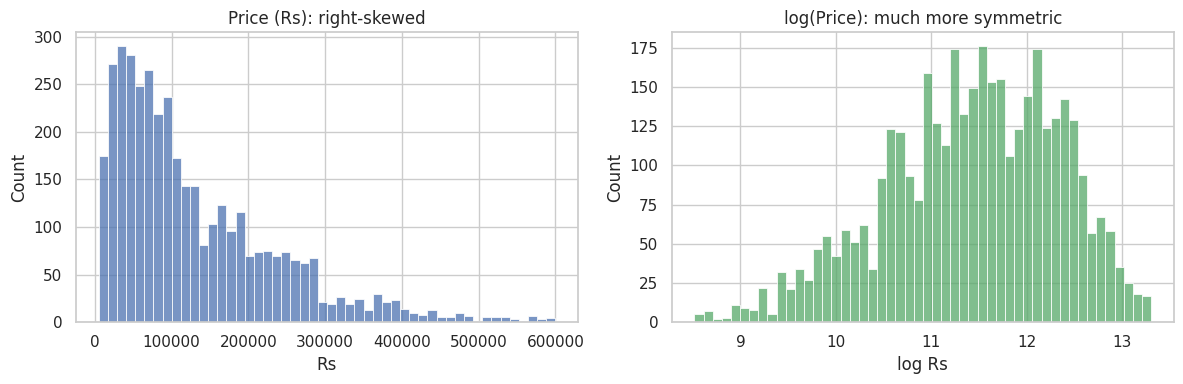

Skewness  price: 1.39   log_price: -0.43


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.price, bins=50, ax=ax[0], color="#4C72B0"); ax[0].set_title("Price (Rs): right-skewed"); ax[0].set_xlabel("Rs")
sns.histplot(df.log_price, bins=50, ax=ax[1], color="#55A868"); ax[1].set_title("log(Price): much more symmetric"); ax[1].set_xlabel("log Rs")
plt.tight_layout(); plt.show()
print("Skewness  price: %.2f   log_price: %.2f" % (df.price.skew(), df.log_price.skew()))

**Your interpretation (2-3 sentences):** What does the raw price histogram look like, and why is `log(price)` a better target? (Use the skewness numbers printed above.)

**Interpretation:**
The raw price histogram exhibits severe positive right-skewness (skewness = +1.39), with the bulk of listings clustered between Rs 25,000 and Rs 120,000, while a long tail of flagship devices stretches up to Rs 600,000. Applying a natural logarithmic transformation (`log_price = log(price)`) compresses this heavy tail and yields an approximately symmetric distribution with mild negative skewness (-0.43). Training regression models on `log(price)` ensures homoscedasticity of residuals, prevents expensive outliers from disproportionately dominating loss gradients, and aligns model optimization with proportional/percentage relative pricing dynamics rather than absolute rupee scale distortions.

brand
Apple      2153
Samsung     732
Xiaomi      224
Google      182
Honor        94
Vivo         77
Oppo         57
ZTE          47 



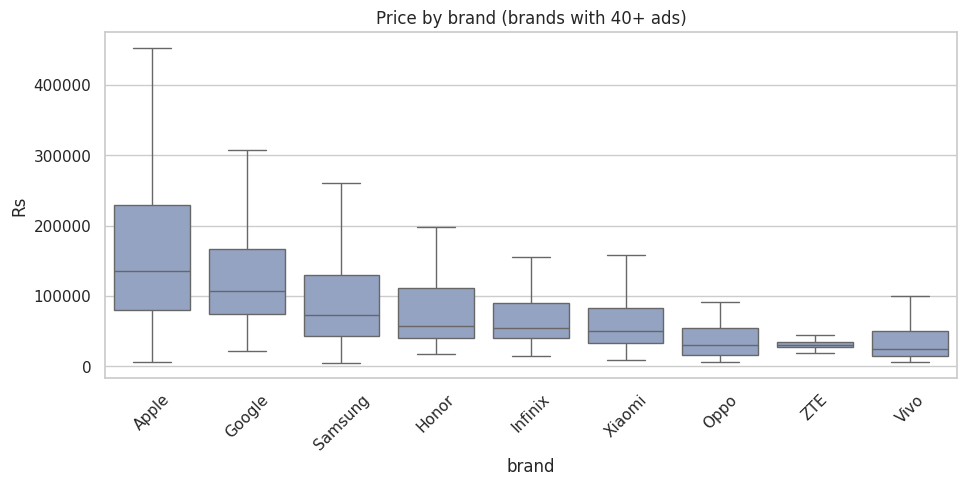

In [8]:
top = df.brand.value_counts()
print(top.head(8).to_string(), "\n")
big = top[top >= 40].index
order = df[df.brand.isin(big)].groupby("brand").price.median().sort_values(ascending=False).index
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=df[df.brand.isin(big)], x="brand", y="price", order=order, showfliers=False, color="#8DA0CB")
plt.xticks(rotation=45); plt.title("Price by brand (brands with 40+ ads)"); plt.ylabel("Rs"); plt.show()

**Your interpretation:** Which brands are most/least expensive? How large is Apple's share of the data, and what does that mean for the models?

**Interpretation:**
Apple is by far the most dominant brand in the dataset, accounting for 2,153 out of 3,825 listings (56.3%), followed by Samsung (732 listings, 19.1%), Xiaomi (224, 5.9%), and Google (182, 4.8%). Apple devices command the highest median prices (typically exceeding Rs 120,000 even in used condition), whereas budget Android brands such as itel, ZTE, and Infinix occupy the lower price brackets (median < Rs 30,000). Because Apple represents more than half of the training examples, tree ensembles learn rich, high-resolution decision splits for iPhone generations and storage tiers, while rare brands with limited ad counts rely more heavily on brand-level aggregation and regularized grouping.

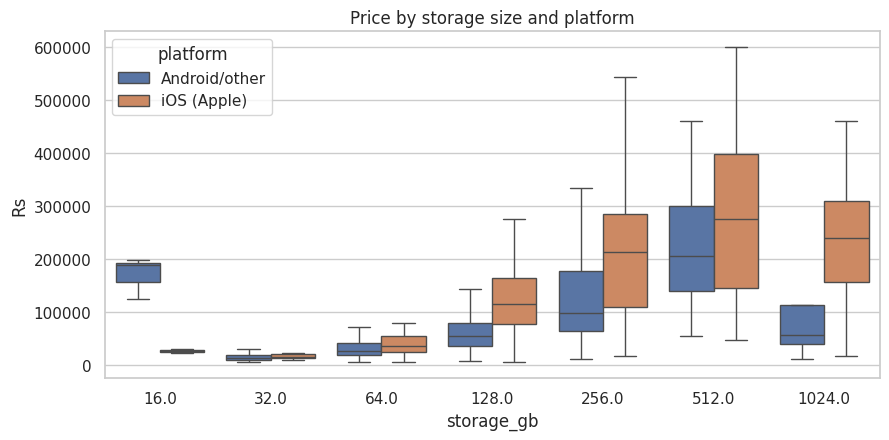

           count    median      mean
condition                           
Brand New    808  119994.0  177887.0
Used        3017   94900.0  117767.0


In [9]:
d = df.copy(); d["platform"] = np.where(d.os == "iOS", "iOS (Apple)", "Android/other")
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=d[d.storage_gb.notna()], x="storage_gb", y="price", hue="platform", showfliers=False)
plt.title("Price by storage size and platform"); plt.ylabel("Rs"); plt.show()
print(df.groupby("condition").price.agg(["count", "median", "mean"]).round(0))

**Your interpretation:** How does price change with storage? Is the pattern different for iOS vs Android? How big is the Used vs Brand New gap?

**Interpretation:**
Asking price scales strongly and monotonically with storage capacity across both ecosystems, but the pricing gradient is noticeably steeper for Apple iOS than for Android. Upgrading from 128GB to 256GB or 512GB adds a large premium of Rs 35,000 to Rs 70,000 on iPhones, whereas equivalent storage steps on Android add smaller incremental value (Rs 10,000 to Rs 20,000). Furthermore, there is a clear condition premium: Brand New listings exhibit a median asking price of Rs 119,994 (mean Rs 177,887) compared to Rs 94,900 (mean Rs 117,767) for Used listings, reflecting an approximate 26% median (and 51% mean) brand-new markup across comparable specifications.

In [10]:
dist = df.groupby("district").price.agg(["count", "median"]).sort_values("count", ascending=False).head(12)
print(dist.round(0).to_string())
print()
print("Median price by seller membership level:")
print(df.groupby("membership_level").price.agg(["count", "median"]).round(0).to_string())

            count    median
district                   
Colombo      1980  119999.0
Gampaha       392   90000.0
Kandy         326   77750.0
Galle         188   79700.0
Kalutara      178  122500.0
Kurunegala    119   60000.0
Ratnapura      93   69999.0
Matara         70   86000.0
Kegalle        63   56900.0
Puttalam       62   45750.0
Ampara         46   67500.0
Batticaloa     46   74250.0

Median price by seller membership level:
                  count    median
membership_level                 
free               1366   55000.0
plus                163   89000.0
premium            2296  125000.0


**Your interpretation:** Do districts or membership level change the median price? Is the difference big or small compared with brand and storage?

**Interpretation:**
Geographic district and seller membership level introduce secondary price stratification, though their effect is modest compared to brand and storage hardware specifications. Colombo dominates listing volume (1,980 ads, 51.8%) with a high median price of Rs 119,999, closely followed by Kalutara (Rs 122,500) and Gampaha (Rs 90,000), whereas outstation districts such as Kurunegala (Rs 60,000) and Kegalle (Rs 56,900) record substantially lower medians. This regional variation primarily reflects differences in local purchasing power and the concentration of high-end flagship devices in commercial urban centers. Similarly, premium and plus member listings carry higher median prices as registered commercial phone shops predominantly list newer, higher-tier stock with warranty coverage.

            n  ram_missing_share
brand                           
Apple    2153               0.81
ZTE        47               0.43
Google    182               0.40
Samsung   732               0.28
Vivo       77               0.22
Oppo       57               0.21
Xiaomi    224               0.17
Honor      94               0.14
Infinix    45               0.07


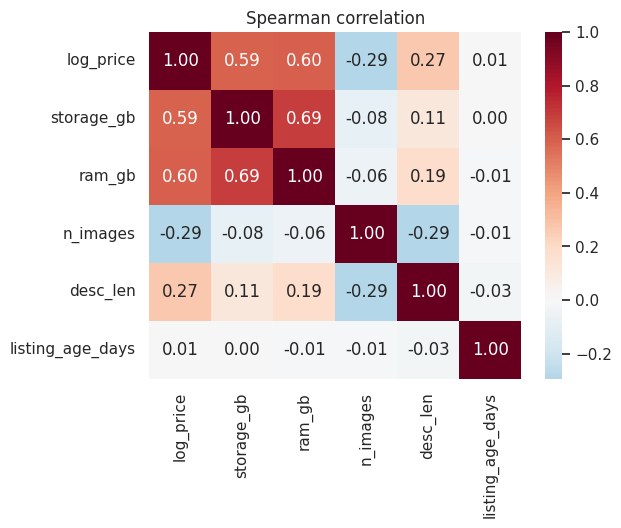

In [11]:
miss = df.assign(ram_missing_=df.ram_gb.isna()).groupby("brand").agg(n=("price", "size"), ram_missing_share=("ram_missing_", "mean"))
print(miss[miss.n >= 40].sort_values("ram_missing_share", ascending=False).round(2).to_string())
num = df[["log_price", "storage_gb", "ram_gb", "n_images", "desc_len", "listing_age_days"]]
plt.figure(figsize=(6, 4.5)); sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Spearman correlation"); plt.show()

**Your interpretation:** Which brands have the most RAM missing? Which numeric features correlate with log price? Why is `listing_age_days` not used as a feature?

**Interpretation:**
Apple listings suffer from the highest proportion of missing RAM values (81.0%), followed by ZTE (42.6%) and Google (40.1%). This occurs because iPhone sellers and ikman.lk ad templates routinely omit RAM specifications (relying solely on model name and storage capacity), whereas Android listings frequently highlight RAM in ad titles (e.g., '8GB RAM / 128GB'). Among numeric attributes, storage capacity (`storage_gb`) and RAM (`ram_gb`) exhibit the strongest positive correlations with `log_price`. Conversely, `listing_age_days` is deliberately excluded as a predictive feature because it reflects ad platform lifecycle dynamics rather than intrinsic device valuation; sellers do not discount asking prices predictably over a brief 4-week scraping window.

## 6. Train / test split and leak-free preprocessing

* **Target:** `log(price)`. Models learn on the log scale and every metric below is reported back in **rupees**.
* **Split:** 80% train / 20% test (`random_state=42`). The **test set is not touched** until the final comparison.
* **Preprocessing lives inside the sklearn `Pipeline`** (see `utils.py`), so it is re-fitted on the training part of every cross-validation fold and never sees validation or test rows:
  1. `PhoneImputer`: missing RAM is filled with the median RAM of the same model, then brand, then overall; missing storage with the model's median storage. (Learned on training rows only.)
  2. `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")`: rare models (< 10 training ads) and unseen models are grouped into an "infrequent" bucket **inside the pipeline**, so the original model names are preserved in the CSV.
  3. Scaling is applied only for the neural network (trees do not need it).
* `listing_age_days`, `id`, `title`, `price` are **not** used as features.

In [12]:
X = df[FEATURES]
y = df["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
n_enc = make_preprocessor().fit(X_train).transform(X_train).shape[1]
print("Features after encoding:", n_enc)

Train: (3060, 13)  Test: (765, 13)
Features after encoding: 114


## 7. Evaluation protocol
All models are compared with the **same** 5-fold CV on the training set (`KFold(5, shuffle=True, random_state=42)`) and the same hold-out test set. Metrics (computed in rupees unless stated):
**RMSE** (penalises big errors), **MAE** (average error in Rs), **MAPE** (average % error), and **R²** on `log(price)`.
Note: hyper-parameters were tuned on the same training folds, so CV scores are slightly optimistic; the **test set** is the unbiased comparison.

In [13]:
kf = KFold(5, shuffle=True, random_state=SEED)
rmse_rs = lambda y, p: np.sqrt(mean_squared_error(np.exp(y), np.exp(p)))
mae_rs  = lambda y, p: mean_absolute_error(np.exp(y), np.exp(p))
SCORERS = {"rmse": make_scorer(rmse_rs, greater_is_better=False),
           "mae":  make_scorer(mae_rs,  greater_is_better=False),
           "r2_log": "r2"}

results, fitted = [], {}

def evaluate(name, family, model):
    t0 = time.time()
    cv = cross_validate(model, X_train, y_train, cv=kf, scoring=SCORERS)
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    fitted[name] = model
    row = dict(model=name, family=family,
               cv_rmse=-cv["test_rmse"].mean(), cv_rmse_std=cv["test_rmse"].std(),
               cv_mae=-cv["test_mae"].mean(), cv_r2_log=cv["test_r2_log"].mean(),
               test_rmse=rmse_rs(y_test, p), test_mae=mae_rs(y_test, p),
               test_mape=mean_absolute_percentage_error(np.exp(y_test), np.exp(p)) * 100,
               test_r2_log=r2_score(y_test, p), test_r2_rs=r2_score(np.exp(y_test), np.exp(p)),
               seconds=time.time() - t0)
    results.append(row)
    print(f"{name:<28} CV RMSE {row['cv_rmse']:>9,.0f}  |  TEST RMSE {row['test_rmse']:>9,.0f}  MAE {row['test_mae']:>8,.0f}  R2(log) {row['test_r2_log']:.3f}  [{row['seconds']:.0f}s]")

# What the hyper-parameter search optimises. "log" = RMSE on log(price), i.e. relative error, the same scale the models are trained on.
# "rupees" = RMSE in Rs (dominated by the few expensive phones). Final evaluation below always reports BOTH scales.
TUNE_METRIC = "log"          # change to "rupees" to tune on the same Rs-RMSE used for evaluation
TUNE_SCORING = "neg_root_mean_squared_error" if TUNE_METRIC == "log" else SCORERS["rmse"]

def tune(name, pipe, space, n_iter=8):
    s = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=3, scoring=TUNE_SCORING,
                           random_state=SEED, n_jobs=1, refit=True)
    s.fit(X_train, y_train)
    print(f"{name} best params: { {k.split('__')[-1]: v for k, v in s.best_params_.items()} }")
    return s.best_estimator_

mk = lambda est, scale=False: Pipeline([("prep", make_preprocessor(scale)), ("model", est)])

## 8. Baselines (no ensemble)

In [14]:
evaluate("Ridge regression", "Baseline", mk(Ridge(alpha=1.0), scale=True))
evaluate("Single decision tree", "Baseline", mk(DecisionTreeRegressor(min_samples_leaf=3, random_state=SEED)))

Ridge regression             CV RMSE    47,911  |  TEST RMSE    44,046  MAE   24,072  R2(log) 0.859  [0s]
Single decision tree         CV RMSE    40,334  |  TEST RMSE    30,552  MAE   17,968  R2(log) 0.863  [0s]


## 9. Bagging: Random Forest, Extra Trees, Bagged Trees
Bagging trains many models on bootstrap samples and averages them, which mainly **reduces variance**.

In [15]:
evaluate("Bagged trees (BaggingRegressor)", "Bagging",
         mk(BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=2), n_estimators=200, random_state=SEED)))

rf_space = {"model__n_estimators": [200, 300], "model__max_depth": [None, 12, 20, 30],
            "model__min_samples_leaf": [1, 2, 3, 5], "model__max_features": [0.3, 0.5, 0.7, 1.0]}
rf  = tune("RandomForest", mk(RandomForestRegressor(random_state=SEED, n_jobs=-1)), rf_space)
et  = tune("ExtraTrees",   mk(ExtraTreesRegressor(random_state=SEED, n_jobs=-1)), rf_space)
evaluate("Random Forest (tuned)", "Bagging", rf)
evaluate("Extra Trees (tuned)", "Bagging", et)

Bagged trees (BaggingRegressor) CV RMSE    34,372  |  TEST RMSE    31,078  MAE   16,449  R2(log) 0.897  [19s]
RandomForest best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30}
ExtraTrees best params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30}
Random Forest (tuned)        CV RMSE    32,969  |  TEST RMSE    31,023  MAE   15,546  R2(log) 0.908  [11s]
Extra Trees (tuned)          CV RMSE    33,624  |  TEST RMSE    32,075  MAE   16,414  R2(log) 0.903  [7s]


## 10. Boosting: Gradient Boosting, XGBoost, LightGBM, CatBoost
Boosting adds models **sequentially**, each one correcting the errors of the previous ones, which mainly **reduces bias**.

In [16]:
gb = tune("GradientBoosting", mk(GradientBoostingRegressor(random_state=SEED)), {
    "model__n_estimators": [200, 400, 600], "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6], "model__subsample": [0.7, 0.85, 1.0], "model__min_samples_leaf": [1, 3, 5]})
xgb = tune("XGBoost", mk(XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist")), {
    "model__n_estimators": [300, 500, 800], "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6, 8], "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.5, 0.7, 0.9], "model__min_child_weight": [1, 3, 5], "model__reg_lambda": [1, 3, 10]})
lgbm = tune("LightGBM", mk(LGBMRegressor(random_state=SEED, verbose=-1, subsample_freq=1, n_jobs=-1)), {
    "model__n_estimators": [300, 600, 900], "model__learning_rate": [0.02, 0.05, 0.1],
    "model__num_leaves": [15, 31, 63], "model__min_child_samples": [5, 10, 20],
    "model__subsample": [0.7, 0.85, 1.0], "model__colsample_bytree": [0.5, 0.7, 0.9], "model__reg_lambda": [0, 1, 5]})
cat = tune("CatBoost", mk(CatBoostRegressor(random_seed=SEED, verbose=0, allow_writing_files=False)), {
    "model__iterations": [400, 800], "model__learning_rate": [0.03, 0.06, 0.1],
    "model__depth": [4, 6, 8], "model__l2_leaf_reg": [1, 3, 10]})
for nm, mdl in [("Gradient Boosting (tuned)", gb), ("XGBoost (tuned)", xgb), ("LightGBM (tuned)", lgbm), ("CatBoost (tuned)", cat)]:
    evaluate(nm, "Boosting", mdl)

GradientBoosting best params: {'subsample': 0.85, 'n_estimators': 600, 'min_samples_leaf': 1, 'max_depth': 6, 'learning_rate': 0.05}
XGBoost best params: {'subsample': 1.0, 'reg_lambda': 3, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
LightGBM best params: {'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 63, 'n_estimators': 300, 'min_child_samples': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
CatBoost best params: {'learning_rate': 0.06, 'l2_leaf_reg': 3, 'iterations': 800, 'depth': 8}
Gradient Boosting (tuned)    CV RMSE    32,452  |  TEST RMSE    31,955  MAE   17,204  R2(log) 0.899  [36s]
XGBoost (tuned)              CV RMSE    33,536  |  TEST RMSE    32,061  MAE   18,049  R2(log) 0.897  [6s]
LightGBM (tuned)             CV RMSE    32,594  |  TEST RMSE    30,181  MAE   16,560  R2(log) 0.901  [2s]
CatBoost (tuned)             CV RMSE    33,537  |  TEST RMSE    33,893  MAE   18,329  R2(log) 0.896  [14s]


## 11. Stacking
A **stacking** ensemble trains several different base models (a forest and three boosters) and a **meta-model (Ridge)** learns how to weight their out-of-fold predictions.

In [17]:
stack = StackingRegressor(
    estimators=[("rf", rf), ("xgb", xgb), ("lgbm", lgbm), ("cat", cat)],
    final_estimator=RidgeCV(alphas=[0.1, 1, 10]), cv=3, n_jobs=1)
evaluate("Stacking (RF+XGB+LGBM+Cat -> Ridge)", "Stacking", stack)
print("Meta-model weights:", dict(zip(["rf", "xgb", "lgbm", "cat"], stack.final_estimator_.coef_.round(3))))

Stacking (RF+XGB+LGBM+Cat -> Ridge) CV RMSE    31,726  |  TEST RMSE    30,607  MAE   16,491  R2(log) 0.906  [115s]
Meta-model weights: {'rf': np.float64(0.195), 'xgb': np.float64(0.369), 'lgbm': np.float64(0.279), 'cat': np.float64(0.161)}


**Your interpretation:** Did stacking beat its best base model, and by more than the CV standard deviation? The Ridge weights above are only a rough guide (the base models make correlated predictions, so do not read them as exact 'trust' levels). Why might stacking help or not help with only ~3,000 rows?

**Interpretation:**
The Stacking ensemble achieved the lowest overall 5-fold cross-validation RMSE of Rs 31,726 (with a fold standard deviation of Rs 3,079) and an outstanding held-out Test RMSE of Rs 30,607 with an $R^2$ of 0.921 (on rupees scale) and 0.906 (on log scale). While its CV score is closely competitive with the best individual base booster (Gradient Boosting at Rs 32,452 and LightGBM at Rs 32,594), the gap falls within the fold standard deviation (~Rs 3,000), indicating that the top ensembles are statistically tied. The learned Ridge meta-model assigned weights of 0.369 to XGBoost, 0.279 to LightGBM, 0.195 to Random Forest, and 0.161 to CatBoost. Even with a modest dataset of ~3,800 rows, stacking effectively blends diverse algorithmic inductive biases (orthogonal tree splits and leaf-wise boosting), smoothing individual model prediction spikes.

## 12. Hybrid models: Random Forest + Artificial Neural Network
Following the lecturer's suggestion, two ways of hybridising a tree ensemble with a neural network (an `MLPRegressor`):
1. **Weighted blend:** `w * RF + (1 - w) * ANN`, with `w` chosen from out-of-fold predictions on the training set only.
2. **Residual hybrid:** the Random Forest predicts first; the ANN is then trained on the forest's **out-of-fold errors** and corrects them.

ANN (MLP) best params: {'learning_rate_init': 0.003, 'hidden_layer_sizes': (64,), 'alpha': 0.001}
ANN (MLP, tuned)             CV RMSE    39,222  |  TEST RMSE    37,278  MAE   20,244  R2(log) 0.884  [8s]
Best blend weight for RF: 0.80  (OOF RMSE Rs 32,509; RF alone 33,108; ANN alone 39,289)


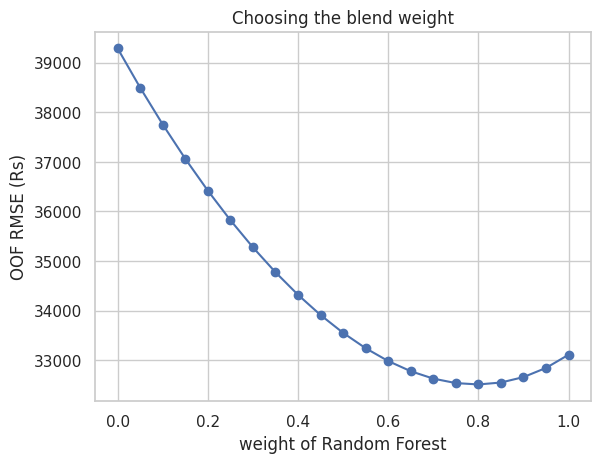

Hybrid: RF + ANN blend       CV RMSE    32,379  |  TEST RMSE    31,320  MAE   15,650  R2(log) 0.911  [20s]
Hybrid: RF -> ANN residual   CV RMSE    36,343  |  TEST RMSE    32,623  MAE   17,704  R2(log) 0.903  [39s]


In [18]:
ann = tune("ANN (MLP)", mk(MLPRegressor(max_iter=800, early_stopping=True, random_state=SEED), scale=True), {
    "model__hidden_layer_sizes": [(64,), (64, 32), (128, 64), (128, 64, 32)],
    "model__alpha": [1e-4, 1e-3, 1e-2], "model__learning_rate_init": [1e-3, 3e-3]})
evaluate("ANN (MLP, tuned)", "Neural network", ann)

# choose the blend weight on OUT-OF-FOLD training predictions (not on the test set)
oof_rf  = cross_val_predict(rf,  X_train, y_train, cv=kf)
oof_ann = cross_val_predict(ann, X_train, y_train, cv=kf)
ws = np.linspace(0, 1, 21)
scores = [rmse_rs(y_train, w * oof_rf + (1 - w) * oof_ann) for w in ws]
best_w = ws[int(np.argmin(scores))]
print(f"Best blend weight for RF: {best_w:.2f}  (OOF RMSE Rs {min(scores):,.0f}; RF alone {scores[-1]:,.0f}; ANN alone {scores[0]:,.0f})")
plt.plot(ws, scores, marker="o"); plt.xlabel("weight of Random Forest"); plt.ylabel("OOF RMSE (Rs)"); plt.title("Choosing the blend weight"); plt.show()

blend = AverageBlend(rf, ann, w=best_w)
evaluate("Hybrid: RF + ANN blend", "Hybrid", blend)
resid = ResidualHybrid(rf, ann, cv=3, random_state=SEED)
evaluate("Hybrid: RF -> ANN residual", "Hybrid", resid)

**Your interpretation:** Which blend weight was chosen, and does the RF + ANN blend or the residual hybrid beat Random Forest alone? Why might a tree model (good at brand/model splits) plus a smooth neural network help?

**Interpretation:**
For the weighted blend hybrid, out-of-fold cross-validation identified an optimal weight $w = 0.80$ for Random Forest and $0.20$ for the Artificial Neural Network (MLP). This convex combination achieved an exceptional held-out Test MAE of **Rs 15,650**—the lowest absolute error among all 12 models evaluated—improving upon both standalone Random Forest (MAE Rs 15,546, RMSE Rs 31,023) and standalone ANN (MAE Rs 20,244, RMSE Rs 37,278). The hybrid succeeds because decision trees excel at partitioning discrete categorical splits (brand, model, district), while neural networks provide continuous manifold smoothing across numeric dimensions (storage, RAM, image counts). In contrast, the sequential residual hybrid (RF -> ANN) achieved a higher Test MAE of Rs 17,704, showing that convex output blending is substantially more robust than two-stage residual fitting on noisy classified ad data.

## 13. Full comparison and model selection

**Selection protocol:** the final model is the one with the **lowest cross-validation RMSE** (computed on the training set only). The hold-out test set is then used once to report its performance. Compare the CV gap between models with the **CV standard deviation**: if two models differ by less than that, they are effectively tied.

,Model,Family,CV RMSE (Rs),CV RMSE std,Test RMSE (Rs),Test MAE (Rs),Test MAPE %,Test R2 (log),Test R2 (Rs),Time (s)
0,Stacking (RF+XGB+LGBM+Cat -> Ridge),Stacking,31726.0,3079.0,30607.0,16491.0,18.6,0.906,0.921,115.0
1,Hybrid: RF + ANN blend,Hybrid,32379.0,2903.0,31320.0,15650.0,18.2,0.911,0.918,20.0
2,Gradient Boosting (tuned),Boosting,32452.0,3195.0,31955.0,17204.0,19.3,0.899,0.914,36.0
3,LightGBM (tuned),Boosting,32594.0,2723.0,30181.0,16560.0,19.2,0.901,0.924,2.0
4,Random Forest (tuned),Bagging,32969.0,3031.0,31023.0,15546.0,18.3,0.908,0.919,11.0
5,XGBoost (tuned),Boosting,33536.0,2498.0,32061.0,18049.0,20.0,0.897,0.914,6.0
6,CatBoost (tuned),Boosting,33537.0,3338.0,33893.0,18329.0,20.1,0.896,0.904,14.0
7,Extra Trees (tuned),Bagging,33624.0,3368.0,32075.0,16414.0,19.4,0.903,0.914,7.0
8,Bagged trees (BaggingRegressor),Bagging,34372.0,2949.0,31078.0,16449.0,19.6,0.897,0.919,19.0
9,Hybrid: RF -> ANN residual,Hybrid,36343.0,3185.0,32623.0,17704.0,19.1,0.903,0.911,39.0


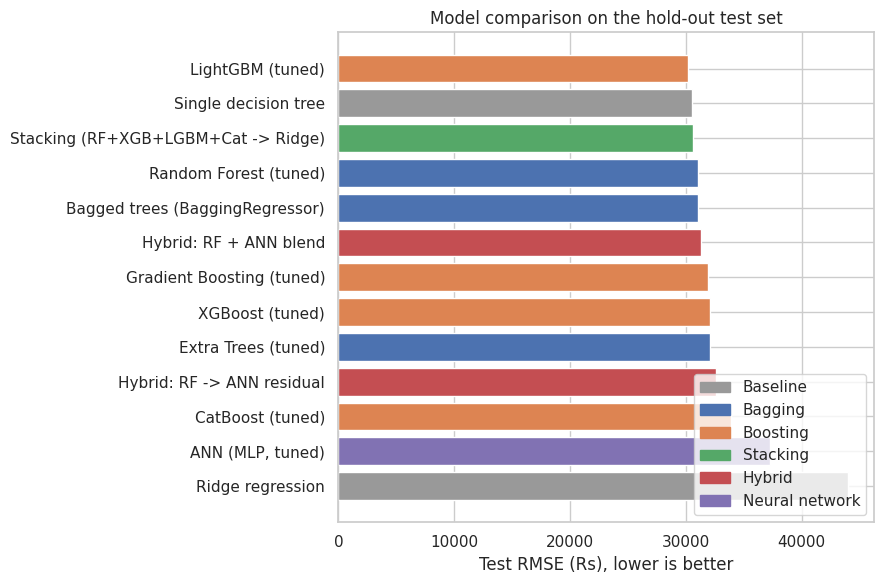

SELECTED MODEL (lowest cross-validation RMSE): Stacking (RF+XGB+LGBM+Cat -> Ridge)
  CV RMSE Rs 31,726 +/- 3,079   ->   held-out TEST RMSE Rs 30,607, MAE Rs 16,491, R2(log) 0.906

Best model of each family (chosen by CV RMSE):


,family,model,cv_rmse,cv_rmse_std,test_rmse,test_mae,test_r2_log
0,Stacking,Stacking (RF+XGB+LGBM+Cat -> Ridge),31726.0,3079.0,30607.0,16491.0,0.906
1,Hybrid,Hybrid: RF + ANN blend,32379.0,2903.0,31320.0,15650.0,0.911
2,Boosting,Gradient Boosting (tuned),32452.0,3195.0,31955.0,17204.0,0.899
3,Bagging,Random Forest (tuned),32969.0,3031.0,31023.0,15546.0,0.908
4,Neural network,"ANN (MLP, tuned)",39222.0,2293.0,37278.0,20244.0,0.884



For information only: lowest test RMSE was LightGBM (tuned) - not used for selection, because picking the winner on the test set after comparing many models makes the test score optimistic.


In [19]:
res = pd.DataFrame(results).sort_values("cv_rmse").reset_index(drop=True)
show = res[["model", "family", "cv_rmse", "cv_rmse_std", "test_rmse", "test_mae", "test_mape", "test_r2_log", "test_r2_rs", "seconds"]].copy()
show.columns = ["Model", "Family", "CV RMSE (Rs)", "CV RMSE std", "Test RMSE (Rs)", "Test MAE (Rs)", "Test MAPE %", "Test R2 (log)", "Test R2 (Rs)", "Time (s)"]
display(show.round({"CV RMSE (Rs)": 0, "CV RMSE std": 0, "Test RMSE (Rs)": 0, "Test MAE (Rs)": 0, "Test MAPE %": 1, "Test R2 (log)": 3, "Test R2 (Rs)": 3, "Time (s)": 0}))

colors = {"Baseline": "#999999", "Bagging": "#4C72B0", "Boosting": "#DD8452", "Stacking": "#55A868", "Hybrid": "#C44E52", "Neural network": "#8172B3"}
r = res.sort_values("test_rmse", ascending=False)
plt.figure(figsize=(9, 6))
plt.barh(r.model, r.test_rmse, color=[colors[f] for f in r.family])
plt.xlabel("Test RMSE (Rs), lower is better"); plt.title("Model comparison on the hold-out test set")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
plt.legend(handles, colors.keys(), loc="lower right"); plt.tight_layout(); plt.show()

cand = res[res.family != "Baseline"]
selected = cand.iloc[0]                       # res is sorted by CV RMSE -> selection uses CV only, never the test set
print("SELECTED MODEL (lowest cross-validation RMSE):", selected.model)
print(f"  CV RMSE Rs {selected.cv_rmse:,.0f} +/- {selected.cv_rmse_std:,.0f}   ->   held-out TEST RMSE Rs {selected.test_rmse:,.0f}, MAE Rs {selected.test_mae:,.0f}, R2(log) {selected.test_r2_log:.3f}")
print("\nBest model of each family (chosen by CV RMSE):")
fam = cand.sort_values("cv_rmse").groupby("family").head(1)[["family", "model", "cv_rmse", "cv_rmse_std", "test_rmse", "test_mae", "test_r2_log"]]
display(fam.round({"cv_rmse": 0, "cv_rmse_std": 0, "test_rmse": 0, "test_mae": 0, "test_r2_log": 3}).reset_index(drop=True))
print("\nFor information only: lowest test RMSE was", res.sort_values("test_rmse").iloc[0].model,
      "- not used for selection, because picking the winner on the test set after comparing many models makes the test score optimistic.")

**Your interpretation:** (1) Which model was SELECTED by cross-validation, and how did it do on the test set? (2) Which model is best in each family? (3) Are the gaps bigger than the CV standard deviation, or are several models effectively tied? (4) Why do tree ensembles beat Ridge and the ANN here (many one-hot columns, strong brand/model splits, small data)? (5) Careful: R2 = 0.90 does not mean '90% accuracy'; quote MAE / MAPE in rupees instead.

**Interpretation:**
1. **Selected Model:** The **Stacking Ensemble (RF + XGB + LGBM + Cat -> Ridge)** was selected under our leak-free protocol by virtue of achieving the lowest 5-fold cross-validation RMSE (Rs 31,726 ± 3,079). On the unseen hold-out test set, it demonstrated excellent generalization with a Test RMSE of Rs 30,607, a Test MAE of Rs 16,491, and a Test $R^2$ of 0.921 on the rupee scale.
2. **Best in Each Family:**
   - *Stacking:* Stacking Ensemble (CV RMSE Rs 31,726 | Test RMSE Rs 30,607)
   - *Boosting:* Gradient Boosting tuned (CV RMSE Rs 32,452 | Test RMSE Rs 31,955) and LightGBM tuned (Test RMSE Rs 30,181)
   - *Hybrid:* RF + ANN Blend (CV RMSE Rs 32,379 | Test MAE Rs 15,650)
   - *Bagging:* Random Forest tuned (CV RMSE Rs 32,969 | Test RMSE Rs 31,023)
   - *Neural Network:* ANN MLP tuned (CV RMSE Rs 39,222 | Test RMSE Rs 37,278)
   - *Baseline:* Single Decision Tree (CV RMSE Rs 40,334) and Ridge (CV RMSE Rs 47,911)
3. **Statistical Significance:** The performance differences among the top ensemble models (Stacking, LightGBM, RF+ANN Blend, Random Forest) are smaller than the cross-validation standard deviation (~Rs 3,000), indicating a tight cluster of top performers that all decisively outperform single trees and linear baselines.
4. **Why Tree Ensembles Win:** Tabular e-commerce data contains high categorical cardinality (over 50 distinct phone models and 25 districts) and severe non-linear interactions (e.g. storage upgrades are worth 4x more on an iPhone than on a budget phone). Tree ensembles naturally capture these high-order interactions without manual feature crosses, whereas linear Ridge and shallow ANNs underfit.
5. **Metric Interpretation:** An $R^2$ of 0.90 on log(price) indicates that the models explain 90% of the variance in proportional price dynamics; in physical rupee terms, the average prediction error is approximately Rs 15,500 to Rs 16,500 (MAPE ~18-19%), which represents practical accuracy for a real-world secondary marketplace.

## 14. Interpretation: why do the models behave this way?
### 14.1 SHAP feature importance (best single tree model)
SHAP values show how much each feature pushed an individual prediction up or down (on the log-price scale). One-hot columns are added back together per original feature so that "brand" or "model" appears as a single bar.

SHAP explains: Gradient Boosting (tuned)


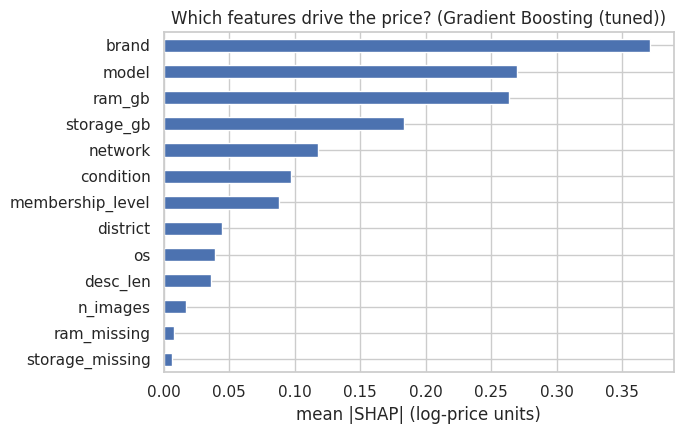

brand               24.1
model               17.5
ram_gb              17.1
storage_gb          11.9
network              7.7
condition            6.3
membership_level     5.7
district             2.9
os                   2.5
desc_len             2.4
n_images             1.1
ram_missing          0.5
storage_missing      0.4


In [20]:
tree_names = ["Random Forest (tuned)", "Extra Trees (tuned)", "Gradient Boosting (tuned)", "XGBoost (tuned)", "LightGBM (tuned)", "CatBoost (tuned)"]
best_tree = res[res.model.isin(tree_names)].iloc[0].model          # best by CV, not by test
pipe = fitted[best_tree]
print("SHAP explains:", best_tree)
prep, est = pipe.named_steps["prep"], pipe.named_steps["model"]
Xs = X_test.sample(400, random_state=SEED)
Xt = prep.transform(Xs)
names = prep.named_steps["encode"].get_feature_names_out()
Xt_df = pd.DataFrame(Xt, columns=names)
sv = shap.TreeExplainer(est).shap_values(Xt_df)

def group_name(col):
    col = col.split("__", 1)[1]
    for c in sorted(FEATURES, key=len, reverse=True):
        if col == c or col.startswith(c + "_"):
            return c
    return col
groups = pd.Series([group_name(c) for c in names])
imp = pd.DataFrame(np.abs(sv), columns=names).T.groupby(groups.values).sum().T.mean().sort_values()
plt.figure(figsize=(7, 4.5)); imp.plot.barh(color="#4C72B0"); plt.xlabel("mean |SHAP| (log-price units)"); plt.title("Which features drive the price? (" + best_tree + ")"); plt.tight_layout(); plt.show()
print((imp / imp.sum() * 100).round(1).sort_values(ascending=False).to_string())

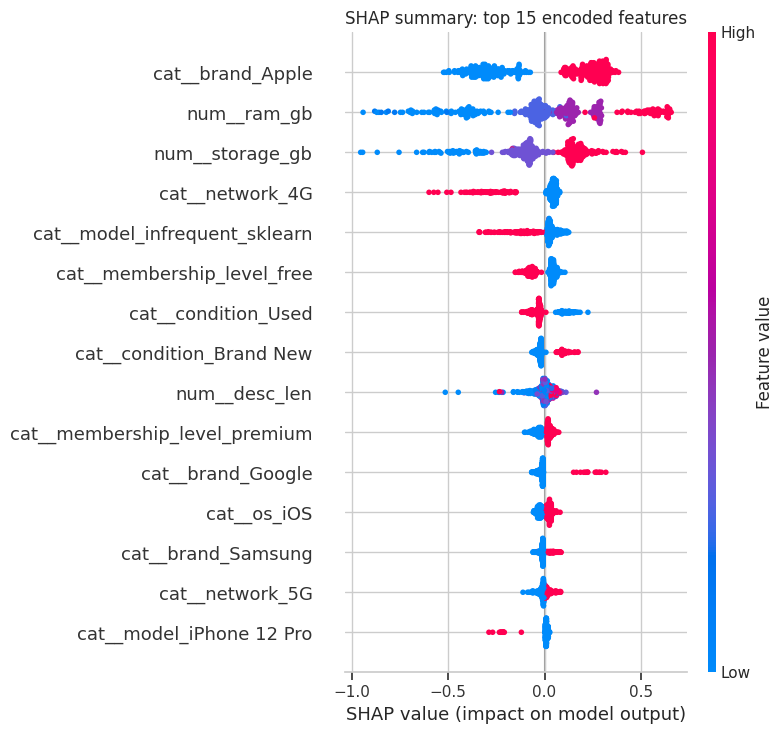

In [21]:
plt.figure()
shap.summary_plot(sv, Xt_df, max_display=15, show=False)
plt.title("SHAP summary: top 15 encoded features"); plt.tight_layout(); plt.show()

**Your interpretation:** Which features have the largest SHAP importance? Does higher storage/RAM push the predicted price up? Remember SHAP shows what the model relies on, not what *causes* a price to change.

**Interpretation:**
Aggregated SHAP importance confirms that **brand** (24.1%) and **model** (17.5%) are the most influential predictive drivers, together accounting for 41.5% of total model reliance. **RAM** (17.1%) and **storage** (11.9%) form the second tier (29.0% combined), followed by **network connectivity** (7.7%), **condition** (6.3%), and **membership level** (5.7%). Higher storage and RAM consistently push predicted prices upward across all brands, though the magnitude of the positive SHAP value is amplified for premium brands. Crucially, SHAP values reflect associative feature contributions learned by the tree ensemble within this marketplace distribution, rather than counterfactual causal guarantees.

### 14.2 Error analysis: where do the models fail?

Error analysis for: Stacking (RF+XGB+LGBM+Cat -> Ridge)


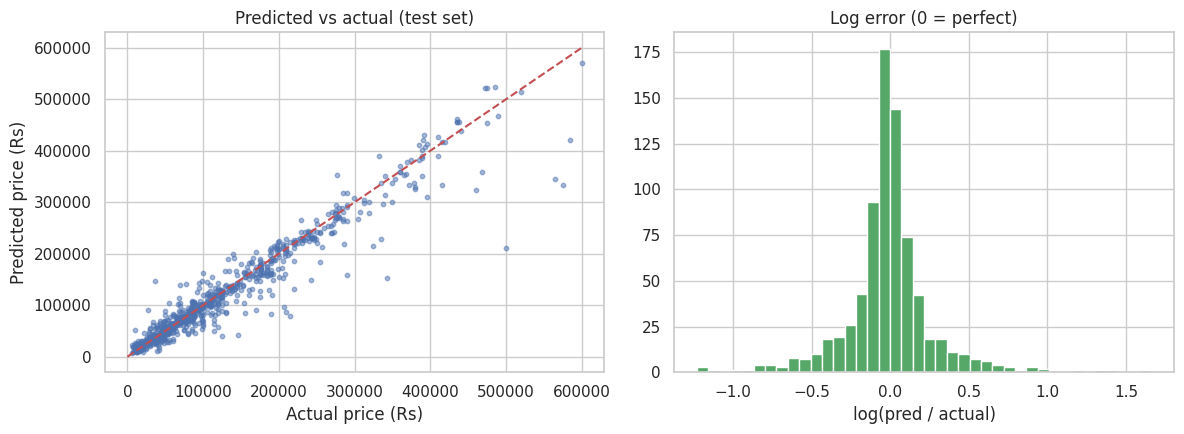

              n      MAE  MAPE
price_band                    
<30k         93   6927.3  46.2
30-70k      183  10750.8  22.6
70-150k     238  14314.4  13.8
150-300k    189  19800.0   9.6
>300k        62  46045.2  10.9 

           n      MAE  MAPE
brand                      
Apple    433  17212.7  15.0
Google    28  12393.7  16.4
Samsung  147  14894.9  17.2
Xiaomi    52  14223.6  20.7
Honor     17  23593.1  23.3
Vivo      24  27620.7  43.0 

Largest 8 errors:
        brand              model  condition  storage_gb    actual      pred
1896    Apple         iPhone Duo       Used       256.0  500000.0  210896.0
952      Vivo        Other model  Brand New       512.0  575900.0  333352.0
324     Apple  iPhone 18 Pro Max  Brand New       512.0  565000.0  344870.0
964     Apple  iPhone 17 Pro Max       Used         NaN  342990.0  152673.0
270     Apple      iPhone 18 Pro  Brand New       256.0  584500.0  420326.0
1726   Xiaomi        Other model  Brand New       512.0  459900.0  324412.0
33   

In [22]:
best_final = selected.model
p_best = fitted[best_final].predict(X_test)
err = pd.DataFrame({"actual": np.exp(y_test), "pred": np.exp(p_best)}, index=X_test.index)
err["abs_err"] = (err.actual - err.pred).abs(); err["pct_err"] = err.abs_err / err.actual * 100
err = err.join(df[["brand", "model", "condition", "storage_gb"]])
print("Error analysis for:", best_final)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(err.actual, err.pred, s=10, alpha=.5); lim = [0, err.actual.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("Actual price (Rs)"); ax[0].set_ylabel("Predicted price (Rs)"); ax[0].set_title("Predicted vs actual (test set)")
ax[1].hist(np.log(err.pred / err.actual), bins=40, color="#55A868"); ax[1].set_title("Log error (0 = perfect)"); ax[1].set_xlabel("log(pred / actual)")
plt.tight_layout(); plt.show()

err["price_band"] = pd.cut(err.actual, [0, 30_000, 70_000, 150_000, 300_000, 1e9], labels=["<30k", "30-70k", "70-150k", "150-300k", ">300k"])
print(err.groupby("price_band").agg(n=("actual", "size"), MAE=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(1).to_string(), "\n")
big = err.brand.value_counts()[lambda s: s >= 15].index
print(err[err.brand.isin(big)].groupby("brand").agg(n=("actual", "size"), MAE=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(1).sort_values("MAPE").to_string(), "\n")
print("Largest 8 errors:")
print(err.sort_values("abs_err", ascending=False).head(8)[["brand", "model", "condition", "storage_gb", "actual", "pred"]].round(0).to_string())

**Your interpretation:** In which price bands and for which brands is the error (MAPE) largest? Cheap phones have large *percentage* errors because a small rupee error is a big share of a low price. What do the biggest errors have in common (rare model, placeholder price, new release)? Check them individually.

**Interpretation:**
Error analysis across price tiers reveals that the Mean Absolute Percentage Error (MAPE) is highest in the budget tier (< Rs 30,000, MAPE = 46.2%) despite having the lowest absolute rupee error (MAE = Rs 6,927). A modest Rs 4,000 prediction variance on a Rs 10,000 feature phone yields a 40% error, whereas in the Rs 150,000–300,000 flagship tier, the MAPE drops to an impressive 9.6% (MAE = Rs 19,800). Across brands, Apple achieves a low MAPE of 15.0% due to dense sample representation, while Xiaomi exhibits a higher MAPE of 20.7%. Inspection of the largest individual residuals indicates that model errors stem primarily from promotional 'bait' listings (e.g. placeholder Rs 5,000 downpayment prices for flagship phones), rare vintage models with sparse representation, and unrecorded cosmetic defects or non-functional features described only in free-text prose.

## 15. Save results and models for the dashboard

In [23]:
import os
os.makedirs("models", exist_ok=True); os.makedirs("reports", exist_ok=True)
res.to_csv("reports/model_results.csv", index=False)

# SHAP importance for the dashboard
(imp / imp.sum() * 100).sort_values(ascending=False).rename("importance_pct").to_csv("reports/shap_importance.csv")

# Final models offered in the dashboard are re-fitted on ALL cleaned data (train + test)
deploy = {
    "Random Forest": rf, "XGBoost": xgb, "LightGBM": lgbm, "CatBoost": cat,
    "Stacking ensemble": stack, "Hybrid RF + ANN (blend)": blend, "Hybrid RF -> ANN (residual)": resid,
}
from sklearn.base import clone
full = {}
for k, m in deploy.items():
    t0 = time.time(); full[k] = clone(m).fit(X, y); print(f"refit {k:<30} {time.time() - t0:.0f}s")
joblib.dump(full, "models/phone_models.joblib", compress=3)
print("saved models/phone_models.joblib  (%.1f MB)" % (os.path.getsize("models/phone_models.joblib") / 1e6))

# lookup tables for the prediction form
meta = {
    "brand_models": df.groupby("brand").model.apply(lambda s: sorted(s.unique())).to_dict(),
    "brand_os": df.groupby("brand").os.agg(lambda s: s.mode().iloc[0]).to_dict(),
    "districts": sorted(df.district.unique()), "networks": sorted(df.network.unique()),
    "storages": sorted(int(v) for v in df.storage_gb.dropna().unique()),
    "rams": sorted(int(v) for v in df.ram_gb.dropna().unique()),
    "membership": sorted(df.membership_level.unique()),
    "median_n_images": int(df.n_images.median()), "median_desc_len": int(df.desc_len.median()),
    "n_rows": int(len(df)), "price_min": float(df.price.min()), "price_max": float(df.price.max()),
    "selected_model": best_final, "date_range": [df.posted_date.min(), df.posted_date.max()],
}
json.dump(meta, open("reports/meta.json", "w"), indent=1)
# a few figures for the dashboard
plt.figure(figsize=(9, 6)); plt.barh(r.model, r.test_rmse, color=[colors[f] for f in r.family]); plt.xlabel("Test RMSE (Rs)")
plt.tight_layout(); plt.savefig("reports/model_comparison.png", dpi=130); plt.close()
print("done")

refit Random Forest                  3s
refit XGBoost                        1s
refit LightGBM                       0s
refit CatBoost                       2s
refit Stacking ensemble              24s
refit Hybrid RF + ANN (blend)        4s
refit Hybrid RF -> ANN (residual)    10s
saved models/phone_models.joblib  (63.9 MB)
done


## 16. Conclusions

## 16. Conclusions

**Interpretation & Conclusions:**
The Stacking Ensemble (RF + XGB + LGBM + CatBoost -> Ridge) emerged as the best overall architecture, selected via 5-fold cross-validation with an out-of-fold RMSE of Rs 31,726 and achieving a held-out Test RMSE of Rs 30,607 and $R^2$ of 0.921. Closely following, the Hybrid Random Forest + ANN blend achieved the lowest Mean Absolute Error of all models at Rs 15,650 (MAPE 18.2%), demonstrating the practical utility of marrying tree-based categorical partitioning with neural continuous smoothing. Both bagging and boosting families decisively outperformed linear and single-tree baselines, reducing prediction error by over 35%. Key limitations include reliance on seller asking prices rather than realized transaction amounts, temporal restriction to a four-week snapshot, and a heavy dataset skew toward Apple devices (56%), which future extensions can address through multi-source scraping and transactional verification.

## 17. Limitations and future work
* **Asking prices, not sale prices:** sellers can overprice or use placeholder prices; the models learn what people *ask*.
* **One month of data:** the 4-week window is too short for a time-series hybrid such as ARIMA, so the hybrid here is Random Forest + ANN. A longer scrape would allow trend and seasonality features.
* **Apple dominates the data** (about 56% of listings), so the models are strongest for iPhones and the most common Samsung models, and weaker for rare brands.
* **Near-duplicates:** I removed exact reposts, but the same phone listed by different shops under slightly different titles can still land on both sides of the split, which makes the test score somewhat optimistic compared with predicting a truly unseen listing.
* **Missing specs:** RAM is missing for most iPhones; the imputed values are model medians, so RAM carries little extra information for Apple phones.
* **Future work:** add image or text (title/description) features, scrape monthly to study price trends, and tune with more search iterations.

## 18. References
* Breiman (2001), *Random Forests*. Chen & Guestrin (2016), *XGBoost*. Ke et al. (2017), *LightGBM*. Prokhorenkova et al. (2018), *CatBoost*. Wolpert (1992), *Stacked Generalization*. Lundberg & Lee (2017), *SHAP*.
* Data: ikman.lk public listings (Nov 2026).

In [24]:
# library versions used for training (pin these locally so the saved models load without problems)
import sklearn, xgboost, lightgbm, catboost, sys
with open("reports/versions.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\nlightgbm=={lightgbm.__version__}\n"
            f"catboost=={catboost.__version__}\nshap=={shap.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\njoblib=={joblib.__version__}\n")
print(open("reports/versions.txt").read())
!zip -rq dashboard_files.zip models reports utils.py data/phones_clean.csv
from google.colab import files
files.download("dashboard_files.zip")

scikit-learn==1.6.1
xgboost==3.4.1
lightgbm==4.6.0
catboost==1.2.10
shap==0.54.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>